In [3]:
import pandas as pd
import numpy as np

np.random.seed(42)
n=1000
df=pd.DataFrame({
    "order_date": pd.date_range("2025-01-01", periods=n, freq="8h"),
    "category": np.random.choice(["Electronics","Clothing","Furniture","Grocery"],n),
    "region": np.random.choice(["North","South","East","West"], n),
    "quantity": np.random.randint(1, 6, n),
    "price": np.random.randint(100, 5000, n),
    "discount": np.random.choice([0, 0.1, 0.2, 0.3], n),
})
df["sales"] = df.quantity * df.price * (1 - df.discount)
df["profit"] = df.sales * np.random.uniform(-0.1, 0.3, n)

df.loc[5:15, "region"] = None
df = pd.concat([df, df.iloc[:10]])

print(df.head())
print(df.info())


           order_date     category region  quantity  price  discount    sales  \
0 2025-01-01 00:00:00    Furniture  South         4   4954       0.0  19816.0   
1 2025-01-01 08:00:00      Grocery   East         3   2949       0.1   7962.3   
2 2025-01-01 16:00:00  Electronics  North         5    875       0.0   4375.0   
3 2025-01-02 00:00:00    Furniture  North         1   4126       0.0   4126.0   
4 2025-01-02 08:00:00    Furniture  North         5   2347       0.3   8214.5   

        profit  
0  4127.613597  
1   565.309447  
2   -76.619541  
3   907.255848  
4   274.715187  
<class 'pandas.core.frame.DataFrame'>
Index: 1010 entries, 0 to 9
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   order_date  1010 non-null   datetime64[ns]
 1   category    1010 non-null   object        
 2   region      994 non-null    object        
 3   quantity    1010 non-null   int64         
 4   price       1010 non

In [4]:
# Pehle problems check
print("Missing:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

# Cleaning
df = df.drop_duplicates()
df["region"] = df["region"].fillna("Unknown")
df = df.reset_index(drop=True)

# Naye columns
df["month"] = df["order_date"].dt.month_name()

# Final check
print("Shape:", df.shape)
print(df.isnull().sum())

Missing:
 order_date     0
category       0
region        16
quantity       0
price          0
discount       0
sales          0
profit         0
dtype: int64
Duplicates: 10
Shape: (1000, 9)
order_date    0
category      0
region        0
quantity      0
price         0
discount      0
sales         0
profit        0
month         0
dtype: int64


In [5]:
# 1. Category-wise sales aur profit
cat = df.groupby("category")[["sales", "profit"]].sum().sort_values("profit", ascending=False)
print(cat)

# 2. Region-wise profit
print(df.groupby("region")["profit"].sum().sort_values(ascending=False))

# 3. Discount ka profit par asar
print(df.groupby("discount")["profit"].mean())

                 sales         profit
category                             
Grocery      1717371.2  179561.605237
Furniture    1560377.1  178618.053356
Electronics  1667613.9  141481.816274
Clothing     1530453.8  130834.596008
region
East       195773.570273
North      162501.240890
South      150417.761540
West       113887.381173
Unknown      7916.116999
Name: profit, dtype: float64
discount
0.0    836.631445
0.1    569.251611
0.2    587.881525
0.3    513.619030
Name: profit, dtype: float64


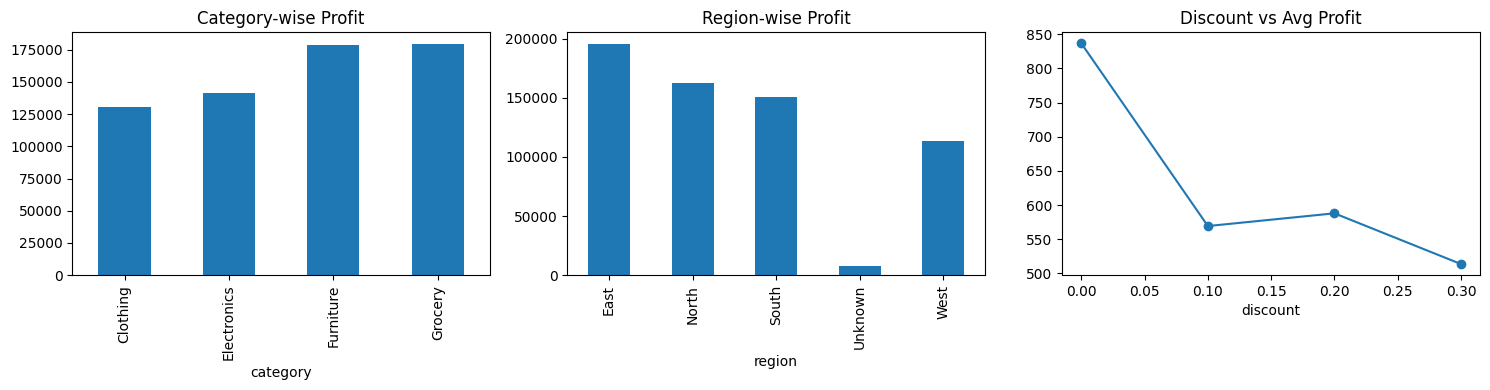

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

df.groupby("category")["profit"].sum().plot(kind="bar", ax=ax[0], title="Category-wise Profit")
df.groupby("region")["profit"].sum().plot(kind="bar", ax=ax[1], title="Region-wise Profit")
df.groupby("discount")["profit"].mean().plot(kind="line", marker="o", ax=ax[2], title="Discount vs Avg Profit")

plt.tight_layout()
plt.show()

               sales        profit
order_date                        
2025-01     604712.7  62866.062601
2025-02     546951.3  60690.955465
2025-03     570775.3  75404.206909
2025-04     552332.6  53163.205049
2025-05     535664.1  50350.222551
2025-06     607443.2  75921.596782
2025-07     594152.0  51648.781671
2025-08     659789.0  63560.332984
2025-09     567758.3  42435.104421
2025-10     645327.1  37920.744549
2025-11     590910.4  56534.857891


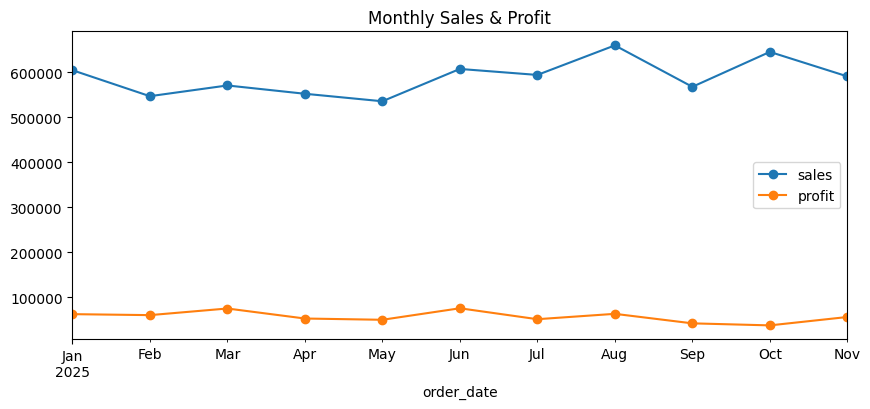

In [7]:
monthly = df.groupby(df["order_date"].dt.to_period("M"))[["sales", "profit"]].sum()
print(monthly)

monthly.plot(kind="line", marker="o", figsize=(10, 4), title="Monthly Sales & Profit")
plt.show()